# Tugas Besar 1  Klasifikasi Biner dengan Perceptron dan ADALINE

**Dataset:** KFC Sales (`kfc_sales_data.xlsx`)

## Tujuan
Melakukan eksperimen klasifikasi dua kelas menggunakan Perceptron dan ADALINE, serta menjelaskan hubungan masalah, fitur masukan, label kelas, model neuron, proses pembelajaran, dan evaluasi.

Perceptron dan ADALINE pada notebook ini **diimplementasikan sendiri dengan NumPy**. Scikit-learn hanya dipakai untuk pembagian data, standardisasi, dan metrik evaluasi.


## 1. Rumusan Masalah

Masalah yang dipilih adalah memprediksi apakah suatu transaksi KFC termasuk **Low Revenue** atau **High Revenue**.

Label dibuat dari median `revenue_usd`, yaitu **$18.10**:
- `0` = Low Revenue, revenue < median
- `1` = High Revenue, revenue >= median

Pendekatan ini membuat masalah menjadi klasifikasi biner dan kedua kelas relatif seimbang.

### Mengapa revenue tidak dimasukkan sebagai fitur?
`revenue_usd` berhubungan langsung dengan `subtotal_usd`, `discount_usd`, dan `delivery_fee_usd`. Jika variabel tersebut dipakai untuk memprediksi label yang dibentuk dari revenue, model akan memperoleh informasi target secara langsung. Untuk mengurangi **data leakage**, semua variabel uang tersebut dikeluarkan dari input model.

### Fitur input
- `hour`
- `items_count`
- `day_of_week`
- `country`
- `city`
- `channel`
- `payment_method`

Fitur kategorikal diubah menjadi one-hot encoding. Fitur numerik kemudian distandardisasi berdasarkan data training.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import os

os.listdir()
SEED = 42
np.random.seed(SEED)

df = pd.read_excel("kfc_sales_data.xlsx")
print("Ukuran data:", df.shape)
print("Kolom:", df.columns.tolist())
df.head()


Ukuran data: (96738, 15)
Kolom: ['transaction_id', 'date', 'day_of_week', 'hour', 'store_id', 'country', 'city', 'channel', 'menu_item', 'items_count', 'payment_method', 'subtotal_usd', 'discount_usd', 'delivery_fee_usd', 'revenue_usd']


,transaction_id,date,day_of_week,hour,store_id,country,city,channel,menu_item,items_count,payment_method,subtotal_usd,discount_usd,delivery_fee_usd,revenue_usd
0,TXN0000001,2025-01-01,Wednesday,20,KFC-USA-NYC-01,USA,New York,Drive-Thru,Combo/Multiple,4,Card,18.0,1.80,0.00,16.20
1,TXN0000002,2025-01-01,Wednesday,11,KFC-USA-NYC-01,USA,New York,Takeaway,Combo/Multiple,5,Mobile Wallet,13.0,0.00,0.00,13.00
2,TXN0000003,2025-01-01,Wednesday,12,KFC-USA-NYC-01,USA,New York,Delivery,Combo/Multiple,3,Cash,48.5,4.85,2.56,46.21
3,TXN0000004,2025-01-01,Wednesday,13,KFC-USA-NYC-01,USA,New York,Delivery,Combo/Multiple,3,Cash,12.5,0.62,1.65,13.53
4,TXN0000005,2025-01-01,Wednesday,13,KFC-USA-NYC-01,USA,New York,Drive-Thru,Combo/Multiple,5,Mobile Wallet,47.0,4.70,0.00,42.30


In [ ]:
import pandas as pd

df = pd.read_excel('/content/kfc_sales_data.xlsx')

print("Ukuran data:", df.shape)
print("Kolom:", df.columns.tolist())

display(df.head())

Ukuran data: (96738, 15)
Kolom: ['transaction_id', 'date', 'day_of_week', 'hour', 'store_id', 'country', 'city', 'channel', 'menu_item', 'items_count', 'payment_method', 'subtotal_usd', 'discount_usd', 'delivery_fee_usd', 'revenue_usd']


,transaction_id,date,day_of_week,hour,store_id,country,city,channel,menu_item,items_count,payment_method,subtotal_usd,discount_usd,delivery_fee_usd,revenue_usd
0,TXN0000001,2025-01-01,Wednesday,20,KFC-USA-NYC-01,USA,New York,Drive-Thru,Combo/Multiple,4,Card,18.0,1.80,0.00,16.20
1,TXN0000002,2025-01-01,Wednesday,11,KFC-USA-NYC-01,USA,New York,Takeaway,Combo/Multiple,5,Mobile Wallet,13.0,0.00,0.00,13.00
2,TXN0000003,2025-01-01,Wednesday,12,KFC-USA-NYC-01,USA,New York,Delivery,Combo/Multiple,3,Cash,48.5,4.85,2.56,46.21
3,TXN0000004,2025-01-01,Wednesday,13,KFC-USA-NYC-01,USA,New York,Delivery,Combo/Multiple,3,Cash,12.5,0.62,1.65,13.53
4,TXN0000005,2025-01-01,Wednesday,13,KFC-USA-NYC-01,USA,New York,Drive-Thru,Combo/Multiple,5,Mobile Wallet,47.0,4.70,0.00,42.30


In [ ]:
print("Missing values:")
print(df.isna().sum())
print("\nJumlah duplikasi:", df.duplicated().sum())
print("\nTipe data:")
print(df.dtypes)


Missing values:
transaction_id      0
date                0
day_of_week         0
hour                0
store_id            0
country             0
city                0
channel             0
menu_item           0
items_count         0
payment_method      0
subtotal_usd        0
discount_usd        0
delivery_fee_usd    0
revenue_usd         0
dtype: int64

Jumlah duplikasi: 0

Tipe data:
transaction_id       object
date                 object
day_of_week          object
hour                  int64
store_id             object
country              object
city                 object
channel              object
menu_item            object
items_count           int64
payment_method       object
subtotal_usd        float64
discount_usd        float64
delivery_fee_usd    float64
revenue_usd         float64
dtype: object


## 2. Pembentukan Label Dua Kelas

Median digunakan sebagai batas karena menghasilkan dua kelompok dengan jumlah data yang hampir sama. Ini lebih sesuai untuk eksperimen klasifikasi biner dibanding membuat kelas berdasarkan batas yang sangat timpang.


In [ ]:
median_revenue = df["revenue_usd"].median()
df["label"] = (df["revenue_usd"] >= median_revenue).astype(int)
df["label_name"] = df["label"].map({0: "Low Revenue", 1: "High Revenue"})

print("Median revenue:", median_revenue)
print("\nJumlah masing-masing kelas:")
print(df["label_name"].value_counts())
print("\nProporsi kelas:")
print(df["label_name"].value_counts(normalize=True).round(4))


Median revenue: 18.1

Jumlah masing-masing kelas:
label_name
High Revenue    48387
Low Revenue     48351
Name: count, dtype: int64

Proporsi kelas:
label_name
High Revenue    0.5002
Low Revenue     0.4998
Name: proportion, dtype: float64


## 3. Feature Engineering dan Pencegahan Data Leakage

`transaction_id` tidak digunakan karena hanya identifier. `subtotal_usd`, `discount_usd`, `delivery_fee_usd`, dan `revenue_usd` juga tidak digunakan sebagai fitur karena berhubungan langsung dengan pembentukan target.

Dengan demikian model harus belajar dari karakteristik transaksi seperti waktu, jumlah item, lokasi, channel, dan metode pembayaran.


In [ ]:
numeric_features = ["hour", "items_count"]
categorical_features = ["day_of_week", "country", "city", "channel", "payment_method"]

X_df = pd.get_dummies(
    df[numeric_features + categorical_features],
    columns=categorical_features,
    dtype=float
)
y = df["label"].values

print("Jumlah fitur setelah one-hot encoding:", X_df.shape[1])
print(X_df.columns.tolist())


Jumlah fitur setelah one-hot encoding: 30
['hour', 'items_count', 'day_of_week_Friday', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'country_Australia', 'country_India', 'country_Pakistan', 'country_UAE', 'country_UK', 'country_USA', 'city_Delhi', 'city_Dubai', 'city_Karachi', 'city_Lahore', 'city_London', 'city_Los Angeles', 'city_New York', 'city_Sydney', 'channel_Delivery', 'channel_Dine-In', 'channel_Drive-Thru', 'channel_Takeaway', 'payment_method_Card', 'payment_method_Cash', 'payment_method_Mobile Wallet']


In [ ]:
X = X_df.values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Ukuran training:", X_train.shape)
print("Ukuran testing :", X_test.shape)
print("Distribusi training:", np.bincount(y_train))
print("Distribusi testing :", np.bincount(y_test))


Ukuran training: (77390, 30)
Ukuran testing : (19348, 30)
Distribusi training: [38681 38709]
Distribusi testing : [9670 9678]


## 4. Implementasi Perceptron

Perceptron menghitung:

`z = wᵀx + b`

Kemudian output ditentukan dengan fungsi threshold. Jika prediksi salah, bobot dan bias diperbarui. Ini merupakan model klasifikasi linear.

Rujukan teori utama: Rosenblatt (1958), *The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain*.


In [ ]:
class Perceptron:
    def __init__(self, learning_rate=0.01, epochs=30):
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, X, y):
        self.weights = np.zeros(X.shape[1])
        self.bias = 0.0
        self.errors_ = []
        target = np.where(y == 1, 1, -1)

        for epoch in range(self.epochs):
            errors = 0
            for xi, yi in zip(X, target):
                activation = np.dot(xi, self.weights) + self.bias
                prediction = 1 if activation >= 0 else -1

                if prediction != yi:
                    self.weights += self.learning_rate * yi * xi
                    self.bias += self.learning_rate * yi
                    errors += 1

            self.errors_.append(errors)

        return self

    def predict(self, X):
        return (X @ self.weights + self.bias >= 0).astype(int)


perceptron = Perceptron(learning_rate=0.01, epochs=30)
perceptron.fit(X_train, y_train)

print("Error 5 epoch pertama:", perceptron.errors_[:5])
print("Error 5 epoch terakhir:", perceptron.errors_[-5:])


Error 5 epoch pertama: [20939, 20950, 20800, 20836, 20830]
Error 5 epoch terakhir: [20811, 20802, 20597, 20926, 20792]


## 5. Implementasi ADALINE

ADALINE (*Adaptive Linear Neuron*) menggunakan output linear sebelum keputusan kelas. Pembelajaran dilakukan dengan meminimalkan **Mean Squared Error (MSE)** menggunakan gradient descent.

Rujukan teori utama: Widrow & Hoff (1960), *Adaptive Switching Circuits*.


In [ ]:
class Adaline:
    def __init__(self, learning_rate=0.01, epochs=100):
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, X, y):
        self.weights = np.zeros(X.shape[1])
        self.bias = 0.0
        self.mse_ = []
        target = np.where(y == 1, 1, -1)

        for epoch in range(self.epochs):
            output = X @ self.weights + self.bias
            error = target - output

            self.weights += self.learning_rate * (X.T @ error) / len(X)
            self.bias += self.learning_rate * error.mean()

            self.mse_.append(np.mean(error ** 2))

        return self

    def predict(self, X):
        return (X @ self.weights + self.bias >= 0).astype(int)


adaline = Adaline(learning_rate=0.01, epochs=100)
adaline.fit(X_train, y_train)

print("MSE awal :", adaline.mse_[0])
print("MSE akhir:", adaline.mse_[-1])


MSE awal : 1.0
MSE akhir: 0.6180509275862376


In [ ]:
def evaluate(model, name):
    pred = model.predict(X_test)

    print(f"=== {name} ===")
    print(f"Accuracy : {accuracy_score(y_test, pred):.4f}")
    print(f"Precision: {precision_score(y_test, pred):.4f}")
    print(f"Recall   : {recall_score(y_test, pred):.4f}")
    print(f"F1-score : {f1_score(y_test, pred):.4f}")
    print("Confusion matrix:")
    print(confusion_matrix(y_test, pred))

    return pred

pred_perceptron = evaluate(perceptron, "Perceptron")
pred_adaline = evaluate(adaline, "ADALINE")


=== Perceptron ===
Accuracy : 0.7375
Precision: 0.7638
Recall   : 0.6880
F1-score : 0.7239
Confusion matrix:
[[7611 2059]
 [3020 6658]]
=== ADALINE ===
Accuracy : 0.8144
Precision: 0.7951
Recall   : 0.8474
F1-score : 0.8204
Confusion matrix:
[[7556 2114]
 [1477 8201]]


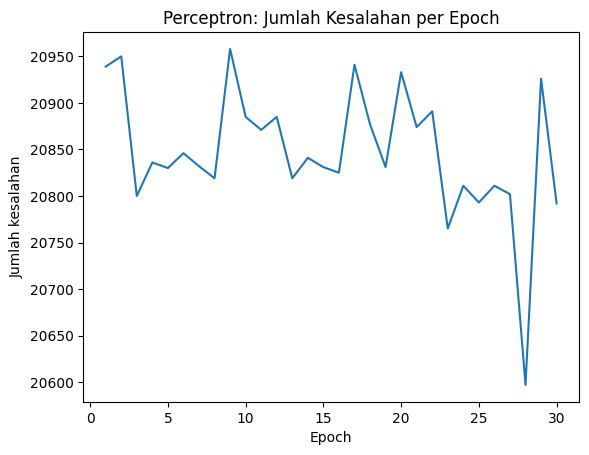

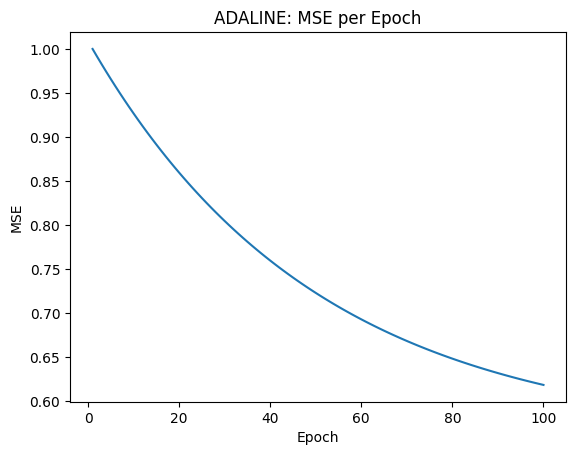

In [ ]:
fig, ax = plt.subplots()
ax.plot(range(1, len(perceptron.errors_) + 1), perceptron.errors_)
ax.set_title("Perceptron: Jumlah Kesalahan per Epoch")
ax.set_xlabel("Epoch")
ax.set_ylabel("Jumlah kesalahan")
plt.show()

fig, ax = plt.subplots()
ax.plot(range(1, len(adaline.mse_) + 1), adaline.mse_)
ax.set_title("ADALINE: MSE per Epoch")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
plt.show()


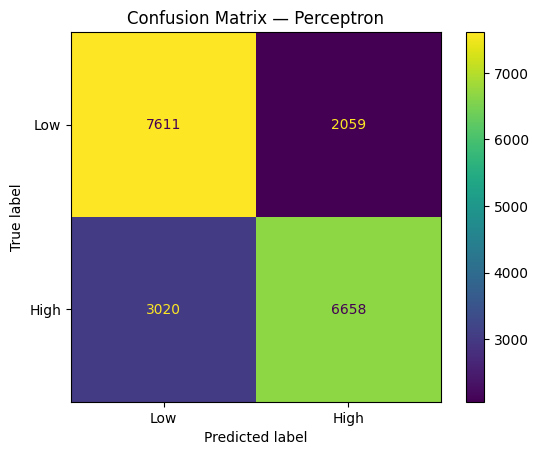

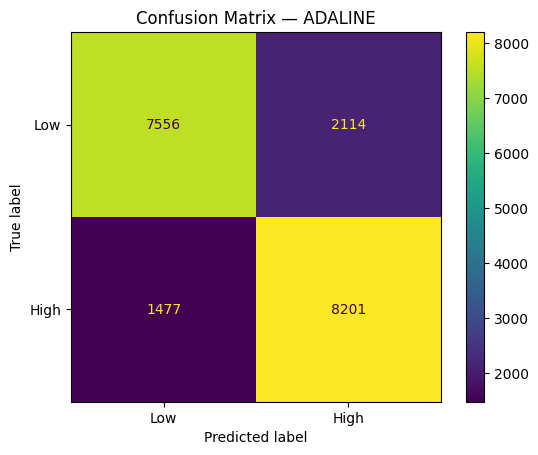

In [ ]:
fig, ax = plt.subplots()
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_perceptron),
    display_labels=["Low", "High"]
).plot(ax=ax)
ax.set_title("Confusion Matrix — Perceptron")
plt.show()

fig, ax = plt.subplots()
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_adaline),
    display_labels=["Low", "High"]
).plot(ax=ax)
ax.set_title("Confusion Matrix — ADALINE")
plt.show()


## 6. Pembahasan

Pada eksperimen ini, **Perceptron memperoleh accuracy sekitar 73,75%**, sedangkan **ADALINE sekitar 81,44%**.

ADALINE memberikan hasil lebih baik pada dataset dan konfigurasi ini. Salah satu alasan teknisnya adalah ADALINE mengoptimalkan error kuadrat dari output linear selama pembelajaran, sedangkan Perceptron hanya melakukan koreksi ketika terjadi salah klasifikasi berdasarkan threshold.

Namun, hasil ini **tidak berarti ADALINE selalu lebih baik**. Kedua metode merupakan model linear sehingga keduanya memiliki keterbatasan apabila pola antara fitur dan kelas sangat non-linear.

Yang penting untuk laporan adalah menghubungkan bukti:
1. learning curve Perceptron menunjukkan perubahan jumlah kesalahan setiap epoch;
2. learning curve ADALINE menunjukkan perubahan MSE;
3. confusion matrix menunjukkan jenis kesalahan klasifikasi;
4. precision, recall, F1-score, dan accuracy memberikan gambaran evaluasi yang lebih lengkap.


## 7. Kesimpulan

1. Dataset KFC berhasil dirumuskan menjadi klasifikasi dua kelas: **Low Revenue** dan **High Revenue**.
2. Median revenue digunakan sebagai batas kelas sehingga distribusi target relatif seimbang.
3. Variabel yang dapat menyebabkan target leakage dikeluarkan dari fitur.
4. Perceptron dan ADALINE diimplementasikan sendiri menggunakan NumPy.
5. Pada eksperimen ini, ADALINE menghasilkan performa lebih tinggi daripada Perceptron.
6. Kinerja model tidak dinilai dari accuracy saja, tetapi juga precision, recall, F1-score, confusion matrix, dan proses pembelajaran.


## 8. Referensi

1. Rosenblatt, F. (1958). *The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain*. Psychological Review, 65(6), 386–408. DOI: 10.1037/h0042519.
2. Widrow, B., & Hoff, M. E. (1960). *Adaptive Switching Circuits*. IRE WESCON Convention Record, pp. 96–104.
3. Scikit-learn documentation, *Perceptron*. Digunakan sebagai referensi implementasi/konsep pembanding, bukan sebagai model utama karena Perceptron dan ADALINE pada notebook ini dibuat sendiri dengan NumPy.
